In [9]:
import pandas as pd
from datetime import datetime
import os
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

In [10]:
# Load the CSV file into a pandas DataFrame
cPath = os.path.dirname(os.path.realpath('./New/'))
file_path = cPath + '/Combined_Terminal_Label.csv'
print(file_path)
myData = pd.read_csv(file_path, parse_dates=['DateTime'], date_format='%Y-%m-%d %H:%M:%S')
myData.set_index('DateTime', drop = False, inplace=True)
# print(myData.head)
print(myData.index.name)
print(myData)

/home/homayoun/Dropbox/Projects/VisualCode/Python/CAE/New/KWH_based/Combined_Terminal_Label.csv
DateTime
                               DateTime  KWH11    KW  Year     Delta     label
DateTime                                                                      
2014-07-01 00:14:00 2014-07-01 00:14:00  357.5  1430  2014  0.005000  sOffPeak
2014-07-01 00:29:00 2014-07-01 00:29:00  362.0  1448  2014 -0.012778  sOffPeak
2014-07-01 00:44:00 2014-07-01 00:44:00  350.5  1402  2014 -0.006667  sOffPeak
2014-07-01 00:59:00 2014-07-01 00:59:00  344.5  1378  2014 -0.022222  sOffPeak
2014-07-01 01:14:00 2014-07-01 01:14:00  324.5  1298  2014 -0.000556  sOffPeak
...                                 ...    ...   ...   ...       ...       ...
2024-12-31 22:59:00 2024-12-31 22:59:00  223.5   894  2024 -0.027778  wOffPeak
2024-12-31 23:14:00 2024-12-31 23:14:00  198.5   794  2024  0.013889  wOffPeak
2024-12-31 23:29:00 2024-12-31 23:29:00  211.0   844  2024  0.008889  wOffPeak
2024-12-31 23:44:00 2024-1

In [11]:
# Convert 15-minute KWH11 data to daily usage by summing values for each day
dailyUsage = myData.groupby(myData['DateTime'].dt.date)['KWH11'].sum().reset_index()
dailyUsage.columns = ['Date', 'Daily_KWH']
dailyUsage['Date'] = pd.to_datetime(dailyUsage['Date'])
dailyUsage.set_index('Date', inplace=True)

print(f"Daily usage data shape: {dailyUsage.shape}")
print(dailyUsage.head())
print(dailyUsage.tail())

Daily usage data shape: (3837, 1)
            Daily_KWH
Date                 
2014-07-01    28243.5
2014-07-02    29073.0
2014-07-03    29247.0
2014-07-04    26586.0
2014-07-05    25597.5
            Daily_KWH
Date                 
2024-12-27    15626.0
2024-12-28    16525.0
2024-12-29    17800.5
2024-12-30    15499.5
2024-12-31    17205.5


In [12]:
# Prepare data for regression: use 7 previous days to predict next day
# Only using Daily_KWH column from dailyUsage

# Create features (X) and target (y)
n_days = 7 

# Extract Daily_KWH column
kwh_data = dailyUsage['Daily_KWH'].values

# Create sequences of 7 days to predict the next day
X = []
y = []

for i in range(len(kwh_data) - n_days):
    X.append(kwh_data[i:i+n_days])
    y.append(kwh_data[i+n_days])

X = np.array(X)
y = np.array(y)

# Split into train and test sets (80-20 split)
split_idx = int(0.8 * len(X))
X_train, X_test = X[:split_idx], X[split_idx:]
y_train, y_test = y[:split_idx], y[split_idx:]

# Train linear regression model
model = LinearRegression()
model.fit(X_train, y_train)

# Make predictions
y_pred = model.predict(X_test)

# Evaluate model
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Training samples: {len(X_train)}")
print(f"Test samples: {len(X_test)}")
print(f"Mean Squared Error: {mse:.4f}")
print(f"R² Score: {r2:.4f}")

Training samples: 3064
Test samples: 766
Mean Squared Error: 1943608.3625
R² Score: 0.7999


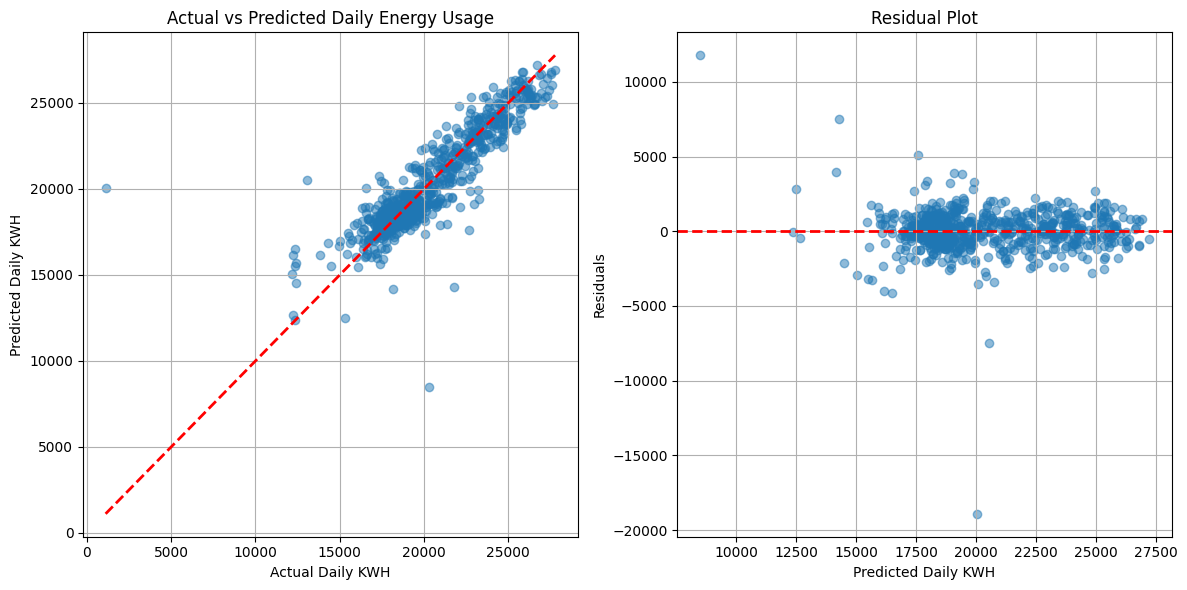

Mean Squared Error: 1943608.3625
R² Score: 0.7999


In [13]:
# Plot predicted vs actual values
plt.figure(figsize=(12, 6))

# Plot actual vs predicted
plt.subplot(1, 2, 1)
plt.scatter(y_test, y_pred, alpha=0.5)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.xlabel('Actual Daily KWH')
plt.ylabel('Predicted Daily KWH')
plt.title('Actual vs Predicted Daily Energy Usage')
plt.grid(True)

# Plot residuals
plt.subplot(1, 2, 2)
residuals = y_test - y_pred
plt.scatter(y_pred, residuals, alpha=0.5)
plt.axhline(y=0, color='r', linestyle='--', lw=2)
plt.xlabel('Predicted Daily KWH')
plt.ylabel('Residuals')
plt.title('Residual Plot')
plt.grid(True)

plt.tight_layout()
plt.show()

print(f"Mean Squared Error: {mse:.4f}")
print(f"R² Score: {r2:.4f}")

In [14]:
from sklearn.svm import SVR

# Train Support Vector Regression model
svm_model = SVR(kernel='rbf', C=100, epsilon=0.1)
svm_model.fit(X_train, y_train)

# Make predictions
y_pred_svm = svm_model.predict(X_test)

# Evaluate model
mse_svm = mean_squared_error(y_test, y_pred_svm)
r2_svm = r2_score(y_test, y_pred_svm)

print(f"SVR Mean Squared Error: {mse_svm:.4f}")
print(f"SVR R² Score: {r2_svm:.4f}")

SVR Mean Squared Error: 2101402.2823
SVR R² Score: 0.7837


In [15]:
from sklearn.neural_network import MLPRegressor

# Train MLP regression model
mlp_model = MLPRegressor(hidden_layer_sizes=(32, 16, 8), activation='relu',
                         solver='adam', max_iter=1000, random_state=42)
mlp_model.fit(X_train, y_train)

# Make predictions
y_pred_mlp = mlp_model.predict(X_test)

# Evaluate model
mse_mlp = mean_squared_error(y_test, y_pred_mlp)
r2_mlp = r2_score(y_test, y_pred_mlp)

print(f"MLP Mean Squared Error: {mse_mlp:.4f}")
print(f"MLP R² Score: {r2_mlp:.4f}")

MLP Mean Squared Error: 1940146.1725
MLP R² Score: 0.8003


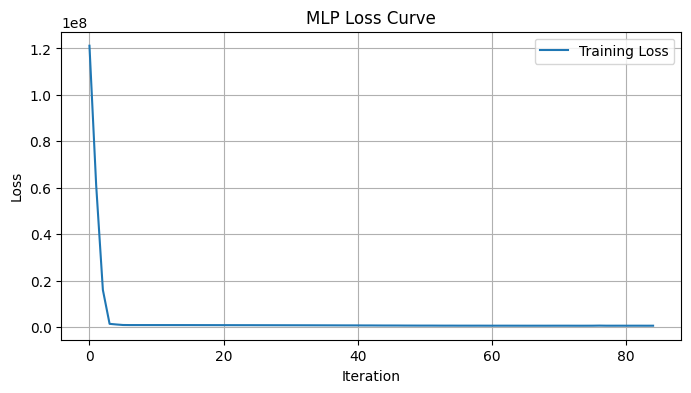

Final MLP training loss: 644059.748997
MLP Test MSE: 1940146.1725


In [16]:
# Plot MLP training loss curve
plt.figure(figsize=(8, 4))
plt.plot(mlp_model.loss_curve_, label='Training Loss')
plt.xlabel('Iteration')
plt.ylabel('Loss')
plt.title('MLP Loss Curve')
plt.grid(True)
plt.legend()
plt.show()

print(f"Final MLP training loss: {mlp_model.loss_curve_[-1]:.6f}")
print(f"MLP Test MSE: {mse_mlp:.4f}")

In [17]:
# Get the date index for the test data (dates corresponding to y_test)
test_dates = dailyUsage.index[n_days + split_idx:]

# Find the split point for 2024
# Create a mask for 2024 data
mask_2024 = dailyUsage.index >= '2024-01-01'

# Find the first index where 2024 starts
first_2024_idx = dailyUsage.index.get_loc(dailyUsage[mask_2024].index[0])

# Calculate the split index accounting for the n_days offset
# We need at least n_days samples before the test set
split_idx_2024 = first_2024_idx - n_days

# Extract Daily_KWH column
kwh_data = dailyUsage['Daily_KWH'].values

# Create sequences of 7 days to predict the next day
X = []
y = []

for i in range(len(kwh_data) - n_days):
    X.append(kwh_data[i:i+n_days])
    y.append(kwh_data[i+n_days])

X = np.array(X)
y = np.array(y)

# Split: data before 2024 for training, 2024 data for testing
X_train, X_test = X[:split_idx_2024], X[split_idx_2024:]
y_train, y_test = y[:split_idx_2024], y[split_idx_2024:]

# Train all three models with the new split

# 1. Linear Regression
model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

# 2. SVR
svm_model = SVR(kernel='rbf', C=100, epsilon=0.1)
svm_model.fit(X_train, y_train)
y_pred_svm = svm_model.predict(X_test)
mse_svm = mean_squared_error(y_test, y_pred_svm)
r2_svm = r2_score(y_test, y_pred_svm)

# 3. MLP
mlp_model = MLPRegressor(hidden_layer_sizes=(32, 16, 8), activation='relu',
                         solver='adam', max_iter=1000, random_state=42)
mlp_model.fit(X_train, y_train)
y_pred_mlp = mlp_model.predict(X_test)
mse_mlp = mean_squared_error(y_test, y_pred_mlp)
r2_mlp = r2_score(y_test, y_pred_mlp)

print(f"Training on data before 2024, Testing on 2024 data")
print(f"Training samples: {len(X_train)}")
print(f"Test samples: {len(X_test)}")
print(f"\nLinear Regression - MSE: {mse:.4f}, R²: {r2:.4f}")
print(f"SVR - MSE: {mse_svm:.4f}, R²: {r2_svm:.4f}")
print(f"MLP - MSE: {mse_mlp:.4f}, R²: {r2_mlp:.4f}")

Training on data before 2024, Testing on 2024 data
Training samples: 3464
Test samples: 366

Linear Regression - MSE: 898978.0488, R²: 0.9083
SVR - MSE: 1008052.3450, R²: 0.8972
MLP - MSE: 934770.0851, R²: 0.9047


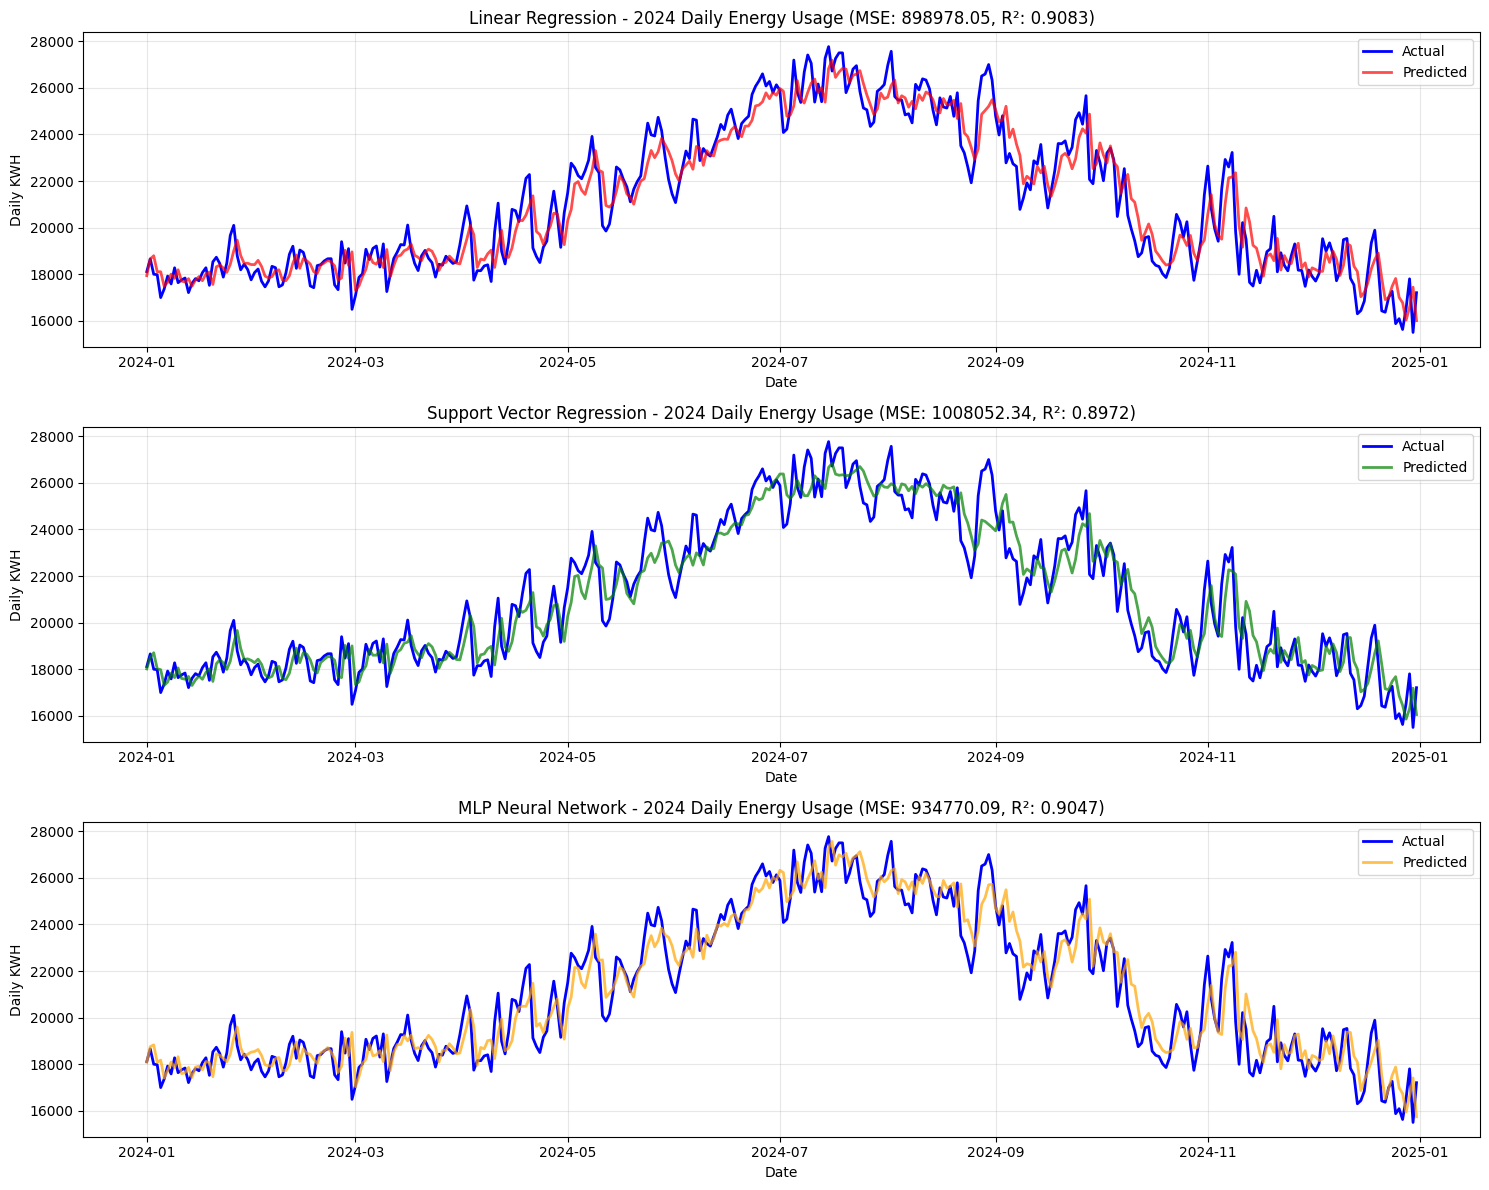

In [18]:
# Get the date index for 2024 test data
test_dates_2024 = dailyUsage.index[n_days + split_idx_2024:]

# Create figure with subplots for each model
fig, axes = plt.subplots(3, 1, figsize=(15, 12))

# Plot Linear Regression
axes[0].plot(test_dates_2024, y_test, label='Actual', color='blue', linewidth=2)
axes[0].plot(test_dates_2024, y_pred, label='Predicted', color='red', linewidth=2, alpha=0.7)
axes[0].set_title(f'Linear Regression - 2024 Daily Energy Usage (MSE: {mse:.2f}, R²: {r2:.4f})')
axes[0].set_xlabel('Date')
axes[0].set_ylabel('Daily KWH')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Plot SVR
axes[1].plot(test_dates_2024, y_test, label='Actual', color='blue', linewidth=2)
axes[1].plot(test_dates_2024, y_pred_svm, label='Predicted', color='green', linewidth=2, alpha=0.7)
axes[1].set_title(f'Support Vector Regression - 2024 Daily Energy Usage (MSE: {mse_svm:.2f}, R²: {r2_svm:.4f})')
axes[1].set_xlabel('Date')
axes[1].set_ylabel('Daily KWH')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

# Plot MLP
axes[2].plot(test_dates_2024, y_test, label='Actual', color='blue', linewidth=2)
axes[2].plot(test_dates_2024, y_pred_mlp, label='Predicted', color='orange', linewidth=2, alpha=0.7)
axes[2].set_title(f'MLP Neural Network - 2024 Daily Energy Usage (MSE: {mse_mlp:.2f}, R²: {r2_mlp:.4f})')
axes[2].set_xlabel('Date')
axes[2].set_ylabel('Daily KWH')
axes[2].legend()
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

    Horizon_Days             Model           MSE        R2
0              1  LinearRegression  8.989780e+05  0.908348
2              1               MLP  9.347701e+05  0.904699
1              1               SVR  1.008052e+06  0.897227
3              2  LinearRegression  1.546008e+06  0.842382
5              2               MLP  1.559088e+06  0.841048
4              2               SVR  1.671023e+06  0.829636
6              3  LinearRegression  1.849292e+06  0.811461
8              3               MLP  1.922821e+06  0.803965
7              3               SVR  1.930786e+06  0.803153
9              5  LinearRegression  2.128109e+06  0.783036
10             5               SVR  2.153719e+06  0.780425
11             5               MLP  2.171404e+06  0.778622


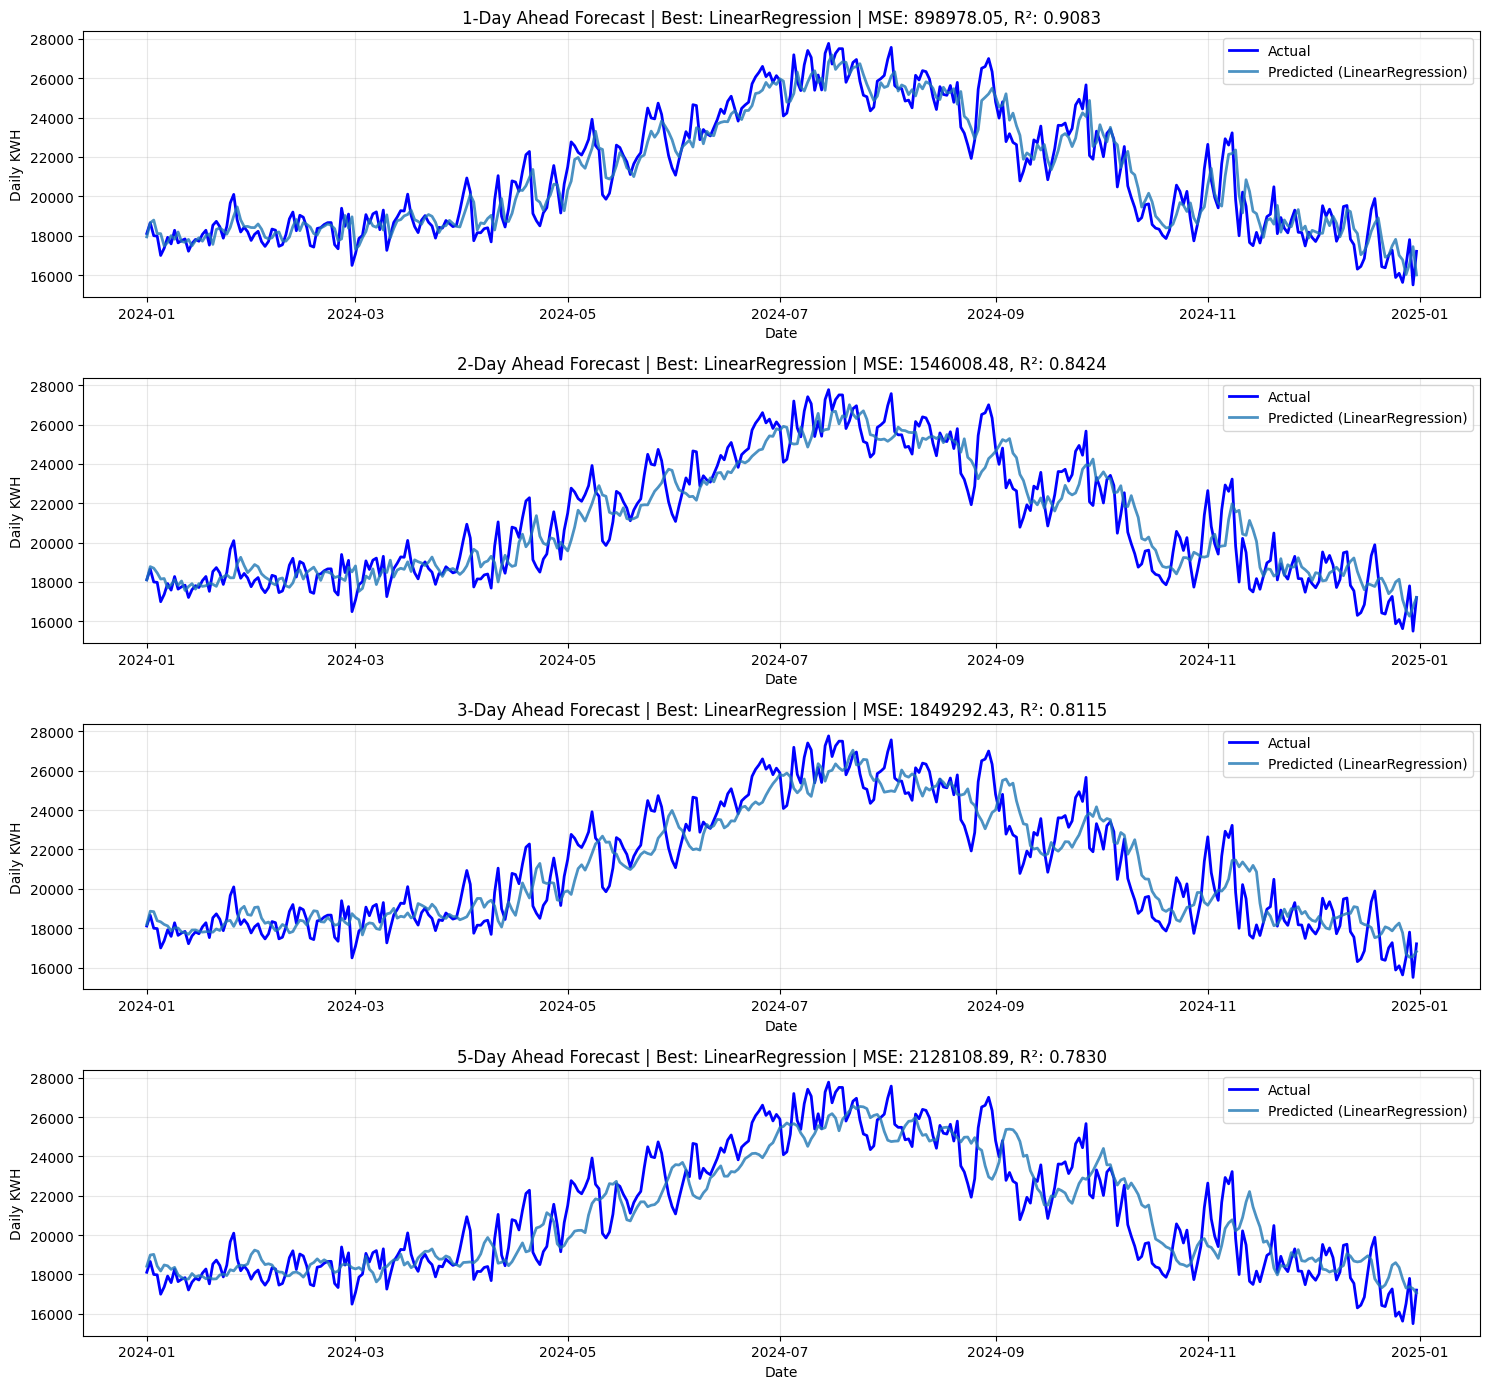

In [19]:
# Multi-horizon forecasting: 1, 2, 3, and 5 days ahead (using previous n_days as features)

horizons = [1, 2, 3, 5]
first_2024_idx = dailyUsage.index.get_loc(dailyUsage[dailyUsage.index >= '2024-01-01'].index[0])
kwh_data = dailyUsage['Daily_KWH'].values

all_results = []
predictions_by_horizon = {}

for h in horizons:
    # Build supervised dataset: X = past n_days, y = value at t + h
    X_h, y_h = [], []
    for i in range(len(kwh_data) - n_days - h + 1):
        X_h.append(kwh_data[i:i+n_days])
        y_h.append(kwh_data[i+n_days+h-1])

    X_h = np.array(X_h)
    y_h = np.array(y_h)

    # Split so test targets start in 2024
    split_idx_h = first_2024_idx - n_days - (h - 1)
    X_train_h, X_test_h = X_h[:split_idx_h], X_h[split_idx_h:]
    y_train_h, y_test_h = y_h[:split_idx_h], y_h[split_idx_h:]
    test_dates_h = dailyUsage.index[n_days + (h - 1) + split_idx_h:]

    # Linear Regression
    lr_h = LinearRegression()
    lr_h.fit(X_train_h, y_train_h)
    y_pred_lr_h = lr_h.predict(X_test_h)

    # SVR
    svr_h = SVR(kernel='rbf', C=100, epsilon=0.1)
    svr_h.fit(X_train_h, y_train_h)
    y_pred_svr_h = svr_h.predict(X_test_h)

    # MLP
    mlp_h = MLPRegressor(hidden_layer_sizes=(32, 16, 8), activation='relu',
                         solver='adam', max_iter=1000, random_state=42)
    mlp_h.fit(X_train_h, y_train_h)
    y_pred_mlp_h = mlp_h.predict(X_test_h)

    # Metrics
    all_results.extend([
        {'Horizon_Days': h, 'Model': 'LinearRegression', 'MSE': mean_squared_error(y_test_h, y_pred_lr_h), 'R2': r2_score(y_test_h, y_pred_lr_h)},
        {'Horizon_Days': h, 'Model': 'SVR', 'MSE': mean_squared_error(y_test_h, y_pred_svr_h), 'R2': r2_score(y_test_h, y_pred_svr_h)},
        {'Horizon_Days': h, 'Model': 'MLP', 'MSE': mean_squared_error(y_test_h, y_pred_mlp_h), 'R2': r2_score(y_test_h, y_pred_mlp_h)},
    ])

    predictions_by_horizon[h] = {
        'dates': test_dates_h,
        'y_test': y_test_h,
        'LinearRegression': y_pred_lr_h,
        'SVR': y_pred_svr_h,
        'MLP': y_pred_mlp_h
    }

# Show summary table
results_df = pd.DataFrame(all_results).sort_values(['Horizon_Days', 'R2'], ascending=[True, False])
print(results_df)

# Plot actual vs predicted for each horizon (best model by R2)
fig, axes = plt.subplots(len(horizons), 1, figsize=(15, 3.5 * len(horizons)), sharex=False)

for ax, h in zip(axes, horizons):
    d = predictions_by_horizon[h]
    subset = results_df[results_df['Horizon_Days'] == h].sort_values('R2', ascending=False).iloc[0]
    best_model = subset['Model']
    best_r2 = subset['R2']
    best_mse = subset['MSE']

    ax.plot(d['dates'], d['y_test'], label='Actual', color='blue', linewidth=2)
    ax.plot(d['dates'], d[best_model], label=f'Predicted ({best_model})', linewidth=2, alpha=0.8)
    ax.set_title(f'{h}-Day Ahead Forecast | Best: {best_model} | MSE: {best_mse:.2f}, R²: {best_r2:.4f}')
    ax.set_xlabel('Date')
    ax.set_ylabel('Daily KWH')
    ax.grid(True, alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()

   Horizon_Days Model           MSE        R2
0             1   SVR  1.008052e+06  0.897227
1             2   SVR  1.671023e+06  0.829636
2             3   SVR  1.930786e+06  0.803153
3             5   SVR  2.153719e+06  0.780425


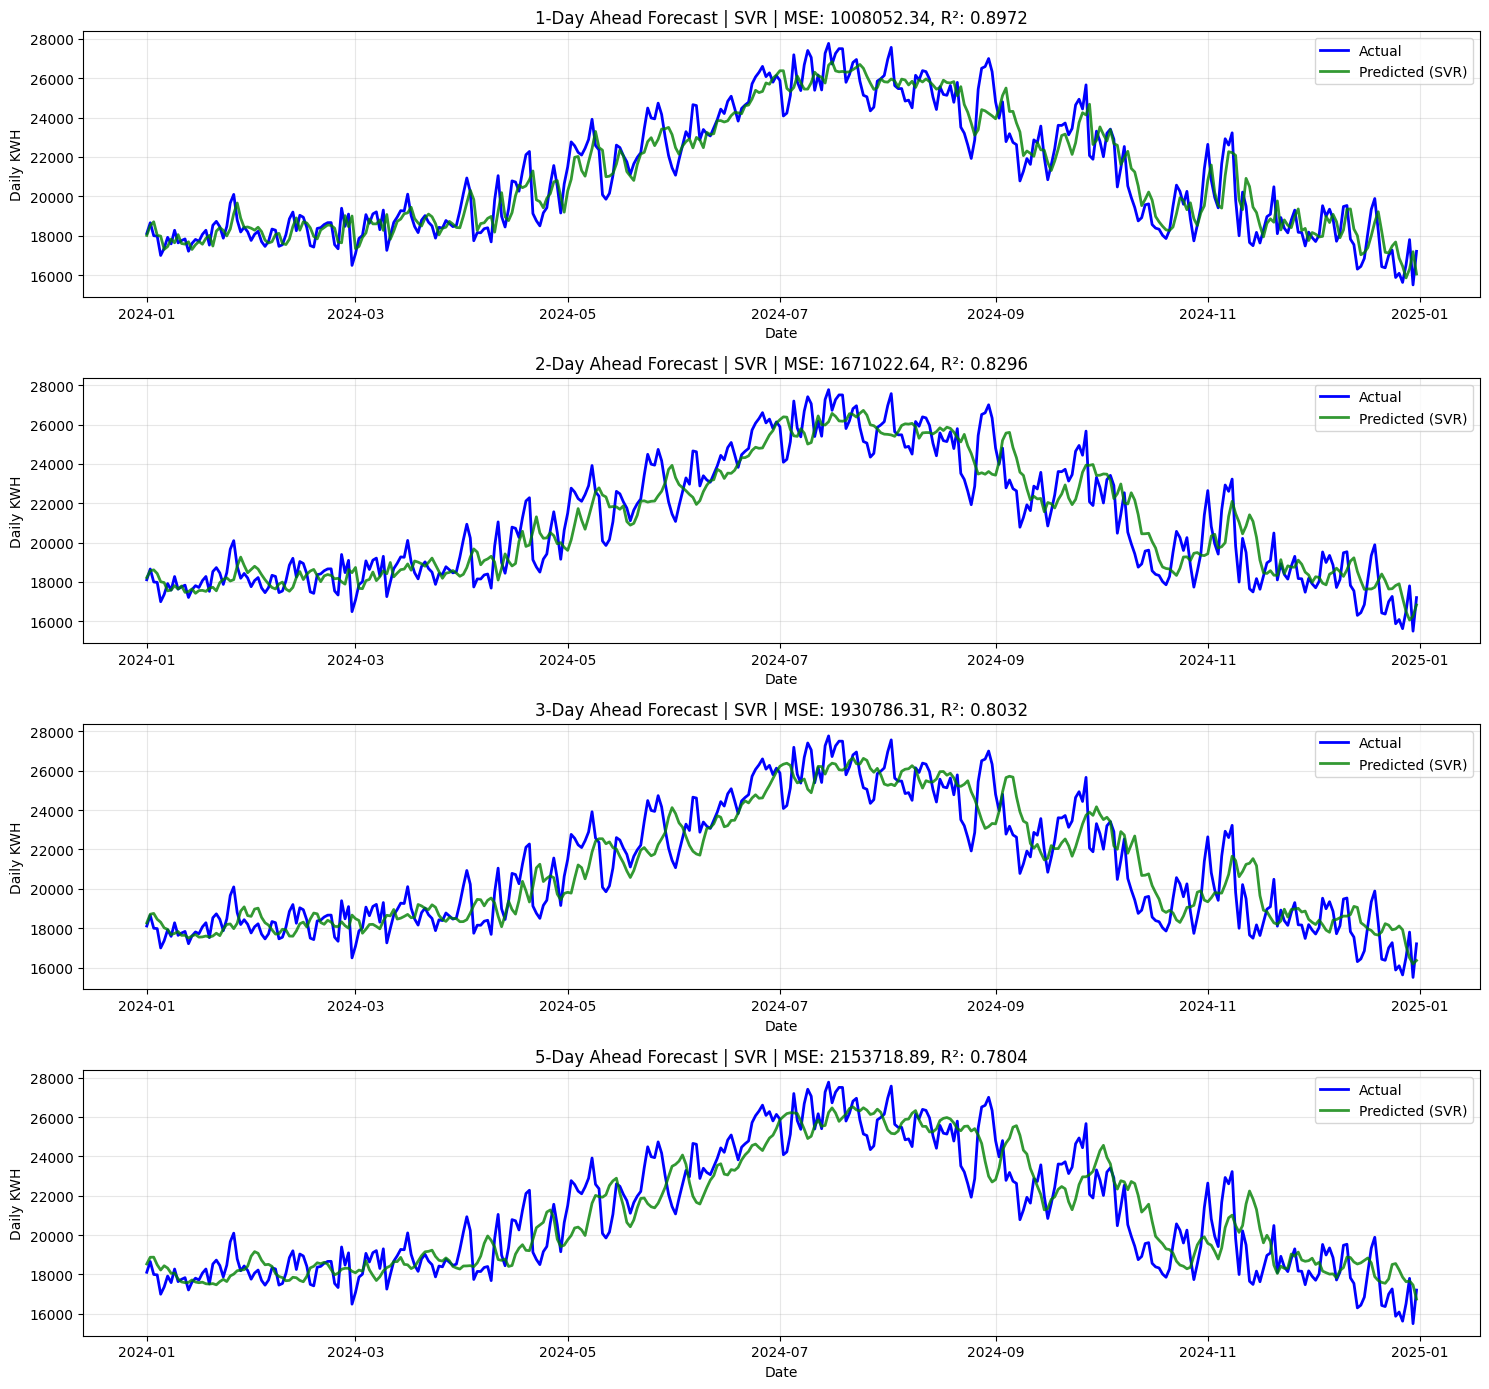

In [20]:
# Repeat multi-horizon results using only SVM (SVR)

svm_results = []
svm_predictions_by_horizon = {}

for h in horizons:
    X_h, y_h = [], []
    for i in range(len(kwh_data) - n_days - h + 1):
        X_h.append(kwh_data[i:i+n_days])
        y_h.append(kwh_data[i+n_days+h-1])

    X_h = np.array(X_h)
    y_h = np.array(y_h)

    split_idx_h = first_2024_idx - n_days - (h - 1)
    X_train_h, X_test_h = X_h[:split_idx_h], X_h[split_idx_h:]
    y_train_h, y_test_h = y_h[:split_idx_h], y_h[split_idx_h:]
    test_dates_h = dailyUsage.index[n_days + (h - 1) + split_idx_h:]

    svr_h = SVR(kernel='rbf', C=100, epsilon=0.1)
    svr_h.fit(X_train_h, y_train_h)
    y_pred_svr_h = svr_h.predict(X_test_h)

    mse_svr_h = mean_squared_error(y_test_h, y_pred_svr_h)
    r2_svr_h = r2_score(y_test_h, y_pred_svr_h)

    svm_results.append({
        'Horizon_Days': h,
        'Model': 'SVR',
        'MSE': mse_svr_h,
        'R2': r2_svr_h
    })

    svm_predictions_by_horizon[h] = {
        'dates': test_dates_h,
        'y_test': y_test_h,
        'y_pred_svr': y_pred_svr_h
    }

svm_results_df = pd.DataFrame(svm_results).sort_values('Horizon_Days')
print(svm_results_df)

# Plot SVM predictions for each horizon
fig, axes = plt.subplots(len(horizons), 1, figsize=(15, 3.5 * len(horizons)), sharex=False)

for ax, h in zip(axes, horizons):
    d = svm_predictions_by_horizon[h]
    row = svm_results_df[svm_results_df['Horizon_Days'] == h].iloc[0]

    ax.plot(d['dates'], d['y_test'], label='Actual', color='blue', linewidth=2)
    ax.plot(d['dates'], d['y_pred_svr'], label='Predicted (SVR)', color='green', linewidth=2, alpha=0.8)
    ax.set_title(f'{h}-Day Ahead Forecast | SVR | MSE: {row["MSE"]:.2f}, R²: {row["R2"]:.4f}')
    ax.set_xlabel('Date')
    ax.set_ylabel('Daily KWH')
    ax.grid(True, alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()

   Horizon_Days Model           MSE        R2
0             1   MLP  9.347701e+05  0.904699
1             2   MLP  1.559088e+06  0.841048
2             3   MLP  1.922821e+06  0.803965
3             5   MLP  2.171404e+06  0.778622


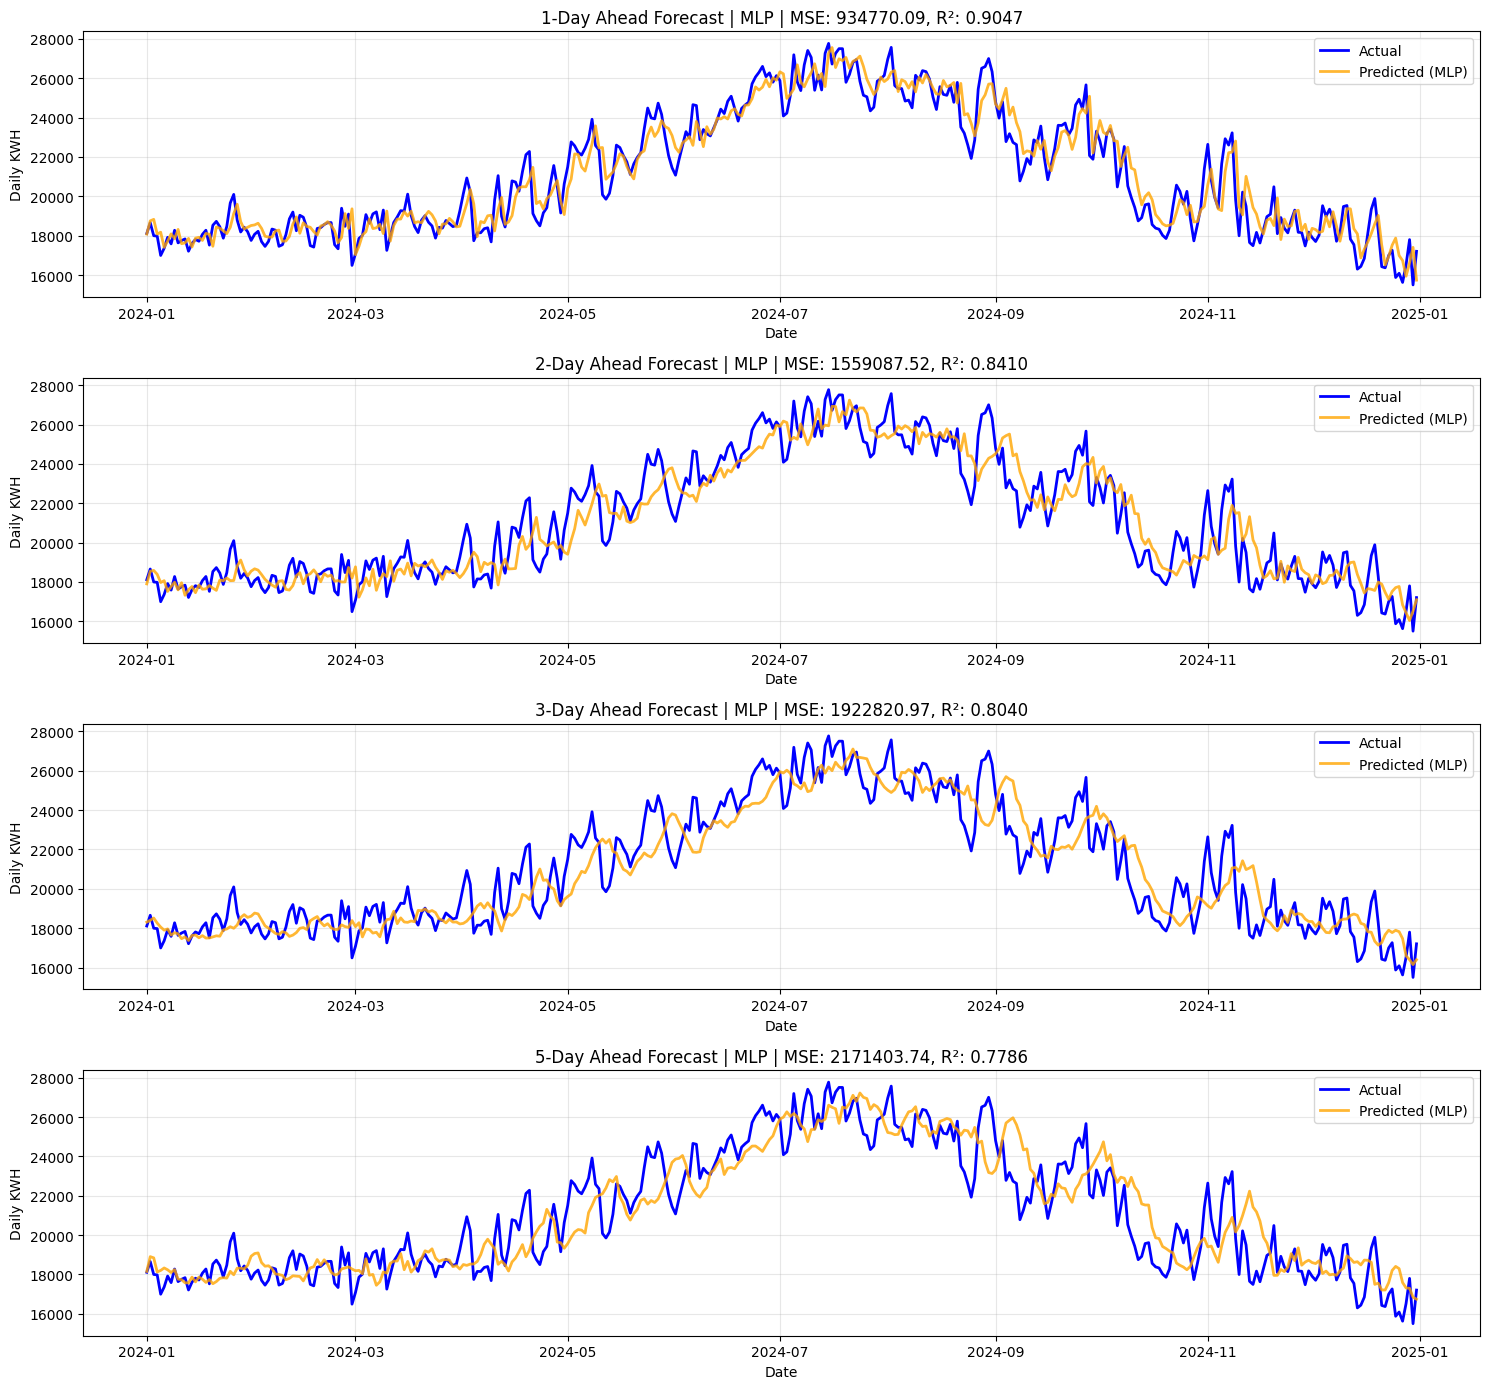

In [21]:
# Repeat multi-horizon results using only MLP

mlp_results = []
mlp_predictions_by_horizon = {}

for h in horizons:
    X_h, y_h = [], []
    for i in range(len(kwh_data) - n_days - h + 1):
        X_h.append(kwh_data[i:i+n_days])
        y_h.append(kwh_data[i+n_days+h-1])

    X_h = np.array(X_h)
    y_h = np.array(y_h)

    split_idx_h = first_2024_idx - n_days - (h - 1)
    X_train_h, X_test_h = X_h[:split_idx_h], X_h[split_idx_h:]
    y_train_h, y_test_h = y_h[:split_idx_h], y_h[split_idx_h:]
    test_dates_h = dailyUsage.index[n_days + (h - 1) + split_idx_h:]

    mlp_h = MLPRegressor(
        hidden_layer_sizes=(32, 16, 8),
        activation='relu',
        solver='adam',
        max_iter=1000,
        random_state=42
    )
    mlp_h.fit(X_train_h, y_train_h)
    y_pred_mlp_h = mlp_h.predict(X_test_h)

    mse_mlp_h = mean_squared_error(y_test_h, y_pred_mlp_h)
    r2_mlp_h = r2_score(y_test_h, y_pred_mlp_h)

    mlp_results.append({
        'Horizon_Days': h,
        'Model': 'MLP',
        'MSE': mse_mlp_h,
        'R2': r2_mlp_h
    })

    mlp_predictions_by_horizon[h] = {
        'dates': test_dates_h,
        'y_test': y_test_h,
        'y_pred_mlp': y_pred_mlp_h
    }

mlp_results_df = pd.DataFrame(mlp_results).sort_values('Horizon_Days')
print(mlp_results_df)

# Plot MLP predictions for each horizon
fig, axes = plt.subplots(len(horizons), 1, figsize=(15, 3.5 * len(horizons)), sharex=False)

for ax, h in zip(axes, horizons):
    d = mlp_predictions_by_horizon[h]
    row = mlp_results_df[mlp_results_df['Horizon_Days'] == h].iloc[0]

    ax.plot(d['dates'], d['y_test'], label='Actual', color='blue', linewidth=2)
    ax.plot(d['dates'], d['y_pred_mlp'], label='Predicted (MLP)', color='orange', linewidth=2, alpha=0.8)
    ax.set_title(f'{h}-Day Ahead Forecast | MLP | MSE: {row["MSE"]:.2f}, R²: {row["R2"]:.4f}')
    ax.set_xlabel('Date')
    ax.set_ylabel('Daily KWH')
    ax.grid(True, alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()